# Asymmetric Uncertainty Decomposition Analysis (Ka=2, Ke=16)

This notebook implements comprehensive uncertainty decomposition, consolidated multi-index benchmark tables (AUROC & PRR with old_max_grouped formatting), and layer ensembling depth sweeps.


In [ ]:
import os
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import glob
import pickle as pkl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold
import warnings
warnings.filterwarnings('ignore')
import seaborn as sns


## 1. Directory Scanning & Setup

In [ ]:
# Configuration - Candidate directories (Unified prioritized, followed by entropies3 and entropies2)
CANDIDATES = [
    '../experiments/result/entropies_unified',
    'src/experiments/result/entropies_unified',
    './result/entropies_unified',
    '../../result/entropies_unified',
    'result/entropies_unified',
    'entropies_unified',
    '../experiments/result/entropies3',
    '../experiments/results/entropies3',
    'src/experiments/result/entropies3',
    'src/experiments/results/entropies3',
    './result/entropies3',
    '../../result/entropies3',
    'result/entropies3',
    'entropies3',
    '../experiments/result/entropies2',
    '../experiments/results/entropies2',
    'src/experiments/result/entropies2',
    'src/experiments/results/entropies2',
    './result/entropies2',
    '../../result/entropies2',
    'result/entropies2',
    'entropies2',
    'src/temp',
    './src/temp',
    '../src/temp',
    'src',
    './src',
    '.'
]

valid_dirs = []
for c in CANDIDATES:
    if os.path.exists(c) and any(f.endswith('.pkl') for f in os.listdir(c)):
        abs_c = os.path.abspath(c)
        if abs_c not in valid_dirs:
            valid_dirs.append(abs_c)

DATA_DIR = valid_dirs[0] if valid_dirs else '.'
print(f"Primary Data Directory: {DATA_DIR}")
print(f"All Valid Candidate Directories: {valid_dirs}")

GLOBAL_CORR_THRESHOLD = 0.1
EVAL_LABEL_KEY = 'bleurt'

# Discover all run files dynamically across valid directories in priority order (entropies_unified > entropies3 > entropies2)
runs = []
seen_run_keys = set()

for d_path in valid_dirs:
    d_files = glob.glob(os.path.join(d_path, "*.pkl"))
    entropy_files = [f for f in d_files if "_entropies_" in os.path.basename(f) or os.path.basename(f).startswith("sdlg_entropies_")]
    for f in sorted(entropy_files):
        base = os.path.basename(f)
        label_file = f.replace("_entropies_", "_label_").replace("sdlg_entropies_", "sdlg_label_")
        if not os.path.exists(label_file):
            if 'qwen-1.5b' in label_file: label_file = label_file.replace('qwen-1.5b', 'qwen2.5-1.5b')
            elif 'qwen2.5-1.5b' in label_file: label_file = label_file.replace('qwen2.5-1.5b', 'qwen-1.5b')
        question_file = f.replace("_entropies_", "_question_").replace("sdlg_entropies_", "sdlg_question_")
        parts = base.replace(".pkl", "").split("_")
        model_name = "unknown"
        dataset_name = "truthfulqa"
        for p in parts:
            p_lower = p.lower()
            if any(m in p_lower for m in ['llama', 'qwen', 'phi', 'opt', 'mistral', 'gemma', 'deepseek']): model_name = p
            if any(d in p_lower for d in ['truth', 'sciq', 'openbook', 'open', 'science', 'scienceqa', 'ambig']):
                dataset_name = 'scienceqa' if 'science' in p_lower or 'sciq' in p_lower else ('openbookqa' if 'open' in p_lower else ('truthfulqa' if 'truth' in p_lower else p_lower))
                
        if os.path.exists(label_file):
            run_key = (dataset_name.lower(), model_name.lower())
            if run_key not in seen_run_keys:
                seen_run_keys.add(run_key)
                runs.append({
                    'name': f"{model_name} on {dataset_name}",
                    'model': model_name,
                    'dataset': dataset_name,
                    'entropy_file': f,
                    'label_file': label_file,
                    'question_file': question_file if os.path.exists(question_file) else None,
                    'dir': d_path
                })

print(f"Discovered {len(runs)} valid evaluation runs across datasets.")
for r in runs:
    print(f"  - [{r['dataset']}] {r['model']} (from {os.path.basename(r['dir'])})")


## 2. Helper to Build Run Dataframe & Grouped Styling

In [ ]:
def safe_extract_label(val, key='bleurt'):
    while isinstance(val, (list, tuple)) and len(val) > 0: val = val[0]
    if isinstance(val, dict):
        if key in val: val = val[key]
        elif 'correctness_dict' in val: val = val['correctness_dict'].get(key, 0.0)
        else:
            for k in ['bleurt_score', 'bleurt', 'rougeL', 'rouge1', 'exact_match']:
                if k in val: val = val[k]; break
            else: val = 0.0
    try:
        fval = float(val)
        return fval if np.isfinite(fval) else 0.0
    except Exception:
        return 0.0

def _to_fixed_array(chunk_or_list, key, N):
    if N <= 0: return np.array([], dtype=float)
    if chunk_or_list is None: return np.full(N, np.nan, dtype=float)
    if isinstance(chunk_or_list, list):
        if key is not None:
            raw = [d.get(key, np.nan) if isinstance(d, dict) else np.nan for d in chunk_or_list[:N]]
        else:
            raw = chunk_or_list[:N]
    else:
        raw = list(chunk_or_list)[:N]
    arr = pd.to_numeric(pd.Series(raw), errors='coerce').values
    if len(arr) < N:
        arr = np.pad(arr, (0, N - len(arr)), constant_values=np.nan)
    elif len(arr) > N:
        arr = arr[:N]
    return arr.astype(float)

def _model_aliases(model):
    m = str(model).lower().replace('_', '-').replace('-instruct', '').replace('-chat', '').strip('-')
    aliases = [m, m.replace('-', '_'), m.replace('-', '')]
    if 'meta-' in m:
        aliases.extend([m.replace('meta-', ''), m.replace('meta-', '').replace('-', '')])
    else:
        aliases.append(f"meta-{m}")

    if 'qwen-1.5b' in m or 'qwen2.5-1.5b' in m:
        aliases.extend(['qwen-1.5b', 'qwen2.5-1.5b', 'qwen_1.5b', 'qwen2.5_1.5b', 'qwen2.5-1.5b-instruct', 'qwen1.5b', 'qwen2.5-1.5'])
    if 'qwen-3b' in m or 'qwen2.5-3b' in m:
        aliases.extend(['qwen-3b', 'qwen2.5-3b', 'qwen_3b', 'qwen2.5_3b', 'qwen2.5-3b-instruct', 'qwen3b', 'qwen2.5-3'])
    if 'qwen-7b' in m or 'qwen2.5-7b' in m:
        aliases.extend(['qwen-7b', 'qwen2.5-7b', 'qwen_7b', 'qwen2.5_7b', 'qwen2.5-7b-instruct', 'qwen7b', 'qwen2.5-7'])
    if 'qwen-14b' in m or 'qwen2.5-14b' in m:
        aliases.extend(['qwen-14b', 'qwen2.5-14b', 'qwen_14b', 'qwen2.5_14b', 'qwen2.5-14b-instruct', 'qwen14b', 'qwen2.5-14'])
    if 'qwen1.5-moe' in m or 'qwen-moe' in m or 'moe' in m:
        aliases.extend(['qwen1.5-moe-a2.7b', 'qwen1.5_moe_a2.7b', 'qwen1.5-moe', 'qwen_moe', 'qwen1.5-moe-chat', 'moe-a2.7b'])
    if 'llama-3.2-3b' in m or 'llama3.2-3b' in m:
        aliases.extend(['llama-3.2-3b', 'llama3.2-3b', 'llama-3-3b', 'llama-3.2-3b-instruct', 'llama3.2_3b', 'llama-3.2', 'llama3.2'])
    if 'llama-3-8b' in m or 'meta-llama-3-8b' in m or 'llama3-8b' in m or 'llama-8b' in m or 'llama8b' in m:
        aliases.extend(['llama-3-8b', 'llama3-8b', 'meta-llama-3-8b', 'meta-llama-3-8b-instruct', 'llama-3-8b-instruct', 'llama-8b', 'llama8b', 'meta-llama-3.1-8b', 'llama-3.1-8b', 'llama3.1-8b', 'meta-llama-3', 'llama3'])
    if 'phi-3-mini' in m or 'phi-3-mini-4k' in m or 'phi-3' in m:
        aliases.extend(['phi-3-mini-4k', 'phi-3-mini', 'phi-3', 'phi-3-mini-4k-instruct', 'phi3'])
    if 'phi-3-medium' in m or 'phi-3-medium-4k' in m:
        aliases.extend(['phi-3-medium-4k', 'phi-3-medium', 'phi-3-medium-4k-instruct', 'phi3-medium'])
    if 'deepseek' in m:
        aliases.extend(['deepseek-moe-16b', 'deepseek_moe_16b', 'deepseek-moe-16b-chat', 'deepseek-moe', 'deepseek'])
    return list(set(aliases))

def _dataset_aliases(dataset):
    d = str(dataset).lower().replace('_', '-')
    aliases = [d, d.replace('-', '_')]
    if any(t in d for t in ['truth', 'truthful', 'truthfulqa']):
        aliases.extend(['truth', 'truthful', 'truthfulqa', 'truthful_qa'])
    elif any(s in d for s in ['science', 'scienceqa', 'sciq']):
        aliases.extend(['science', 'scienceqa', 'science_qa', 'sciq'])
    elif any(o in d for o in ['open', 'openbook', 'openbookqa']):
        aliases.extend(['open', 'openbook', 'openbookqa', 'openbook_qa'])
    return list(set(aliases))

def resolve_metric_candidates(chunk, candidate_keys, N):
    if not chunk or N <= 0: return np.full(N, np.nan, dtype=float)
    if isinstance(candidate_keys, str): candidate_keys = [candidate_keys]
    first_d = next((d for d in chunk if isinstance(d, dict)), {})
    for ck in candidate_keys:
        if ck in first_d or any(isinstance(d, dict) and ck in d for d in chunk[:N]):
            vals = [d.get(ck, np.nan) if isinstance(d, dict) else np.nan for d in chunk[:N]]
            return _to_fixed_array(vals, None, N)
    base_key = candidate_keys[0]
    alts = [k for k in first_d.keys() if k.startswith(f"{base_key}_") or base_key in k]
    if alts:
        alts.sort(key=lambda x: int(x.split('_')[-1]) if x.split('_')[-1].isdigit() else 999)
        vals = [d.get(alts[0], np.nan) if isinstance(d, dict) else np.nan for d in chunk[:N]]
        return _to_fixed_array(vals, None, N)
    return np.full(N, np.nan, dtype=float)

def load_run_data(run):
    with open(run['entropy_file'], 'rb') as f: raw_entropies = pkl.load(f)
    with open(run['label_file'], 'rb') as f: raw_labels = pkl.load(f)
    
    questions = []
    if run.get('question_file') and os.path.exists(run['question_file']):
        try:
            with open(run['question_file'], 'rb') as f: questions = pkl.load(f)
        except Exception:
            pass
            
    raw_labels_len = len(raw_labels)
    raw_ent_len = len(raw_entropies) if isinstance(raw_entropies, list) else 0
    
    if raw_ent_len >= int(2.5 * raw_labels_len) and raw_labels_len > 0:
        num_instances = raw_labels_len
        ours_entropies = raw_entropies[0 : num_instances]
        sdlg_entropies = raw_entropies[num_instances : 2*num_instances]
        kuhn_entropies = raw_entropies[2*num_instances : 3*num_instances]
    else:
        num_instances = min(raw_labels_len, raw_ent_len) if raw_ent_len > 0 else raw_labels_len
        ours_entropies = raw_entropies[0 : num_instances] if raw_ent_len >= num_instances else []
        sdlg_entropies = None
        kuhn_entropies = None

    m_aliases = _model_aliases(run.get('model', ''))
    d_aliases = _dataset_aliases(run.get('dataset', 'truthfulqa'))
    
    # 1. HYBRID FALLBACK: If SE chunks are missing (e.g. DATA_DIR is entropies3 or entropies_unified), lookup entropies2
    has_se = (ours_entropies and any(isinstance(d, dict) and 'normalised_semantic_entropy' in d for d in ours_entropies))
    if sdlg_entropies is None or kuhn_entropies is None or not has_se:
        candidate_e2_dirs = [
            '../experiments/result/entropies2',
            '../experiments/results/entropies2',
            'src/experiments/result/entropies2',
            'src/experiments/results/entropies2',
            './result/entropies2',
            '../../result/entropies2',
            '../experiments/result/entropies3',
            'src/experiments/result/entropies3',
            'result/entropies2',
            'result/entropies3',
            'entropies2',
            'entropies3',
            'src/temp',
            './src/temp',
            '../src/temp'
        ]
        for e2_dir in candidate_e2_dirs:
            if not os.path.exists(e2_dir): continue
            for fname in os.listdir(e2_dir):
                fl = fname.lower()
                if ('_entropies_' in fl or fl.startswith('sdlg_entropies_')) and any(ma in fl for ma in m_aliases) and any(da in fl for da in d_aliases):
                    e2_path = os.path.join(e2_dir, fname)
                    if os.path.abspath(e2_path) == os.path.abspath(run['entropy_file']):
                        continue
                    try:
                        with open(e2_path, 'rb') as fp: e2_raw = pkl.load(fp)
                        if isinstance(e2_raw, list) and len(e2_raw) >= int(2.5 * num_instances):
                            if sdlg_entropies is None: sdlg_entropies = e2_raw[num_instances : 2*num_instances]
                            if kuhn_entropies is None: kuhn_entropies = e2_raw[2*num_instances : 3*num_instances]
                            if not has_se:
                                ours_se_c = e2_raw[0:num_instances]
                                for idx_i in range(min(len(ours_entropies), len(ours_se_c))):
                                    if isinstance(ours_entropies[idx_i], dict) and isinstance(ours_se_c[idx_i], dict) and 'normalised_semantic_entropy' in ours_se_c[idx_i]:
                                        ours_entropies[idx_i]['normalised_semantic_entropy'] = ours_se_c[idx_i]['normalised_semantic_entropy']
                                has_se = True
                            break
                        elif isinstance(e2_raw, list) and len(e2_raw) >= num_instances and not has_se:
                            ours_se_c = e2_raw[0:num_instances]
                            if any(isinstance(d, dict) and 'normalised_semantic_entropy' in d for d in ours_se_c):
                                for idx_i in range(min(len(ours_entropies), len(ours_se_c))):
                                    if isinstance(ours_entropies[idx_i], dict) and isinstance(ours_se_c[idx_i], dict) and 'normalised_semantic_entropy' in ours_se_c[idx_i]:
                                        ours_entropies[idx_i]['normalised_semantic_entropy'] = ours_se_c[idx_i]['normalised_semantic_entropy']
                                has_se = True
                    except Exception:
                        pass
            if sdlg_entropies is not None and kuhn_entropies is not None and has_se:
                break

    labels = _to_fixed_array([safe_extract_label(l, EVAL_LABEL_KEY) for l in raw_labels[:num_instances]], None, num_instances)
    our_se = _to_fixed_array(ours_entropies, 'normalised_semantic_entropy', num_instances)
    sdlg_se = _to_fixed_array(sdlg_entropies, 'normalised_semantic_entropy', num_instances) if sdlg_entropies is not None else our_se
    kuhn_se = _to_fixed_array(kuhn_entropies, 'normalised_semantic_entropy', num_instances)
    q_list = questions[:num_instances] if len(questions) >= num_instances else (questions + [f"Q{i}" for i in range(len(questions), num_instances)])

    df = pd.DataFrame({
        'Question': q_list[:num_instances],
        'Correctness': labels,
        'Is_Correct': (pd.Series(labels) >= GLOBAL_CORR_THRESHOLD).astype(int),
        'Our_Weighted_SE': our_se,
        'entropy_final': resolve_metric_candidates(ours_entropies, ['entropy_final', 'entropy_final_top_8'], num_instances),
        'entropy_mixture': resolve_metric_candidates(ours_entropies, ['entropy_mixture_top_2', 'entropy_mixture_2', 'entropy_mixture_depth_2', 'entropy_mixture_0', 'entropy_mixture_top_8', 'entropy_mixture'], num_instances),
        'mutual_info': resolve_metric_candidates(ours_entropies, ['mutual_info_top_16', 'mutual_info_16', 'mutual_info_depth_16', 'mutual_info_15', 'mutual_info', 'mutual_info_top_8'], num_instances),
        'mutual_info_top_16': resolve_metric_candidates(ours_entropies, ['mutual_info_top_16', 'mutual_info_16', 'mutual_info_depth_16', 'mutual_info_15', 'mutual_info_top_8', 'mutual_info'], num_instances),
        'gated_mutual_info': resolve_metric_candidates(ours_entropies, ['gated_mutual_info_top_16', 'gated_mutual_info_top_8', 'gated_mutual_info', 'gated_mutual_info_top_24'], num_instances),
        'gated_mutual_info_depth_75': resolve_metric_candidates(ours_entropies, ['gated_mutual_info_depth_75', 'gated_mutual_info_75', 'gated_mutual_info_top_24', 'gated_mutual_info_top_21'], num_instances),
        'jsd': resolve_metric_candidates(ours_entropies, ['jsd_top_16', 'jsd_top_8', 'jsd'], num_instances),
        'kl': resolve_metric_candidates(ours_entropies, ['kl_top_16', 'kl_top_8', 'kl'], num_instances),
        'epkl': resolve_metric_candidates(ours_entropies, ['epkl_top_16', 'epkl_top_8', 'epkl'], num_instances),
        'tvd': resolve_metric_candidates(ours_entropies, ['tvd_top_16', 'tvd_top_8', 'tvd'], num_instances),
        'cv': resolve_metric_candidates(ours_entropies, ['cv_top_16', 'cv_top_8', 'cv'], num_instances),
        'bhattacharyya': resolve_metric_candidates(ours_entropies, ['bhattacharyya_top_16', 'bhattacharyya_top_8', 'bhattacharyya'], num_instances),
        'SDLG_Baseline_SE': sdlg_se,
        'SDLG_SE': sdlg_se,
        'Semantic_Entropy': sdlg_se,
        'Kuhn_Baseline_SE': kuhn_se,
        'Kuhn_SE': kuhn_se,
    })

    # External TokUR and ICE baselines
    candidate_tokur_roots = [
        os.path.join(DATA_DIR, '..', 'tokur', 'result') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'tokur') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'entropies_unified') if DATA_DIR else '.',
        './tokur/result', './tokur',
        '../experiments/tokur/result', '../experiments/tokur',
        'src/experiments/tokur/result', 'src/experiments/tokur',
        './result/tokur', 'results/tokur', 'result/tokur',
        'result/entropies_unified', './result/entropies_unified', 'entropies_unified',
        'entropies3', 'entropies2', '.'
    ]
    candidate_ice_roots = [
        os.path.join(DATA_DIR, '..', 'ice', 'result') if DATA_DIR else '.',
        os.path.join(DATA_DIR, '..', 'ice') if DATA_DIR else '.',
        './ice/result', './ice',
        '../experiments/ice/result', '../experiments/ice',
        'src/experiments/ice/result', 'src/experiments/ice',
        './result/ice', 'results/ice', 'result/ice',
        'entropies3', 'entropies2', '.'
    ]

    tokur_found = False
    for troot in candidate_tokur_roots:
        if tokur_found or not os.path.exists(troot): continue
        for root_dir, dirs, files in os.walk(troot):
            sorted_files = sorted(files, key=lambda x: (0 if 'entrop' in x.lower() else (1 if 'tokur' in x.lower() else 2)))
            for fname in sorted_files:
                fl = fname.lower()
                r_lower = root_dir.lower()
                if 'checkpoint' in fl or 'checkpoint' in r_lower:
                    continue
                if ('tokur' in fl or 'tokur' in r_lower) and any(ma in fl or ma in r_lower for ma in m_aliases) and any(da in fl or da in r_lower for da in d_aliases):
                    if fl.endswith('.pkl'):
                        tpath = os.path.join(root_dir, fname)
                        try:
                            with open(tpath, 'rb') as fp: tent = pkl.load(fp)
                            if isinstance(tent, list) and len(tent) > 0:
                                def _ext_tok(e, k1, k2):
                                    if not isinstance(e, dict): return np.nan
                                    sub = e.get('entropy_dict', e) if isinstance(e.get('entropy_dict'), dict) else e
                                    return sub.get(k1, sub.get(k2, np.nan))
                                tok_au = _to_fixed_array([_ext_tok(e, 'tokur_au', 'entropy_final') for e in tent], None, num_instances)
                                tok_mi = _to_fixed_array([_ext_tok(e, 'tokur_mi', 'mutual_info') for e in tent], None, num_instances)
                                if np.isfinite(tok_au).any() or np.isfinite(tok_mi).any():
                                    df['tokur_au'] = tok_au
                                    df['tokur_mi'] = tok_mi
                                    df['tokur_total'] = np.where(np.isfinite(tok_au) & np.isfinite(tok_mi), tok_au + tok_mi, np.nan)
                                    tokur_found = True
                                    break
                        except Exception: pass
            if tokur_found: break

    ice_found = False
    for iroot in candidate_ice_roots:
        if ice_found or not os.path.exists(iroot): continue
        for root_dir, dirs, files in os.walk(iroot):
            for fname in files:
                fl = fname.lower()
                r_lower = root_dir.lower()
                if ('ice' in fl or 'ice' in r_lower) and any(ma in fl or ma in r_lower for ma in m_aliases) and any(da in fl or da in r_lower for da in d_aliases):
                    if fl.endswith('.csv') or fl.endswith('.pkl'):
                        ipath = os.path.join(root_dir, fname)
                        try:
                            idf = pd.read_csv(ipath) if fl.endswith('.csv') else pd.DataFrame(pkl.load(open(ipath, 'rb')))
                            if 'aleatoric_uncertainty' in idf.columns:
                                df['ice_aleatoric'] = _to_fixed_array(idf['aleatoric_uncertainty'].values, None, num_instances)
                            if 'epistemic_uncertainty' in idf.columns:
                                df['ice_epistemic'] = _to_fixed_array(idf['epistemic_uncertainty'].values, None, num_instances)
                            if 'total_uncertainty' in idf.columns:
                                df['ice_total'] = _to_fixed_array(idf['total_uncertainty'].values, None, num_instances)
                            elif 'ice_aleatoric' in df.columns and 'ice_epistemic' in df.columns:
                                df['ice_total'] = df['ice_aleatoric'] + df['ice_epistemic']
                            if 'ice_aleatoric' in df.columns or 'ice_total' in df.columns or 'ice_epistemic' in df.columns:
                                ice_found = True
                                break
                        except Exception: pass
            if ice_found: break

    # Extract layerwise ensembling keys for sweep charts
    first_d = next((d for d in ours_entropies if isinstance(d, dict)), {})
    
    # 1. Map all entropy mixture depths (up to physical model depth <= 48)
    em_found_keys = [k for k in first_d.keys() if ('entropy_mixture' in k) and any(c.isdigit() for c in k)]
    for key in em_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 48:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'entropy_mixture_{idx_k}'] = df[key]
            
    # 2. Map all mutual info depths (up to physical model depth <= 48)
    mi_found_keys = [k for k in first_d.keys() if ('mutual_info' in k and 'gated' not in k) and any(c.isdigit() for c in k)]
    for key in mi_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 48:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'mutual_info_{idx_k}'] = df[key]

    # 3. Map all gated mutual info depths
    gmi_found_keys = [k for k in first_d.keys() if ('gated_mutual_info' in k) and any(c.isdigit() for c in k)]
    for key in gmi_found_keys:
        df[key] = _to_fixed_array([d.get(key, 0.0) if isinstance(d, dict) else 0.0 for d in ours_entropies], None, num_instances)
        digits = ''.join(c for c in key.split('_')[-1] if c.isdigit())
        if digits and int(digits) <= 48:
            idx_k = int(digits) - 1 if int(digits) > 0 else 0
            df[f'gated_mutual_info_{idx_k}'] = df[key]
            
    return df, raw_entropies, labels

def get_curves_and_metrics(df, uncertainty_col, threshold=GLOBAL_CORR_THRESHOLD):
    df['Is_Correct'] = (df['Correctness'] >= threshold).astype(int)
    u_raw = pd.to_numeric(df[uncertainty_col], errors='coerce')
    c_raw = pd.to_numeric(df['Correctness'], errors='coerce')
    valid_mask = u_raw.notna() & c_raw.notna() & np.isfinite(u_raw) & np.isfinite(c_raw)
    df_clean = df[valid_mask].copy()
    
    if len(df_clean) < 2:
        return [0.0, 1.0], [0.0, 1.0], np.nan, np.nan, np.linspace(0.01, 1.0, 100), [], [], 0.0
        
    correct = df_clean['Is_Correct'].values
    u_val = pd.to_numeric(df_clean[uncertainty_col], errors='coerce').values
    N = len(correct)
    a0 = correct.mean()
    
    try:
        if len(np.unique(correct)) > 1:
            fpr, tpr, _ = roc_curve(1 - correct, u_val)
            auroc = roc_auc_score(1 - correct, u_val)
        else:
            fpr, tpr, auroc = [0.0, 1.0], [0.0, 1.0], 0.500
    except Exception:
        fpr, tpr, auroc = [0.0, 1.0], [0.0, 1.0], 0.500

    try:
        correct_sorted = df_clean.sort_values(by=uncertainty_col, ascending=True)['Is_Correct'].values
        coverages = np.linspace(0.01, 1.0, 100)
        accuracies_method = [correct_sorted[:max(1, int(N * cov))].mean() for cov in coverages]
        accuracies_oracle = [min(max(1, int(N * cov)), correct.sum()) / max(1, int(N * cov)) for cov in coverages]
        area_method = np.trapz(accuracies_method, coverages)
        area_oracle = np.trapz(accuracies_oracle, coverages)
        area_baseline = a0
        prr = (area_method - area_baseline) / (area_oracle - area_baseline + 1e-10)
    except Exception:
        prr = 0.0
        coverages, accuracies_method, accuracies_oracle = np.linspace(0.01, 1.0, 100), [], []
        
    return fpr, tpr, auroc, prr, coverages, accuracies_method, accuracies_oracle, a0

def calculate_auroc_and_prr(df, uncertainty_col, threshold=GLOBAL_CORR_THRESHOLD):
    fpr, tpr, auroc, prr, _, _, _, _ = get_curves_and_metrics(df, uncertainty_col, threshold)
    return auroc, prr

def bold_max_grouped(df):
    if df.empty:
        return df
    level0_groups = []
    for col in df.columns:
        if col[0] not in level0_groups:
            level0_groups.append(col[0])
    boundary_col_indices = []
    for grp in level0_groups[:-1]:
        grp_indices = [i for i, col in enumerate(df.columns) if col[0] == grp]
        if grp_indices:
            boundary_col_indices.append(grp_indices[-1])
    def _highlight_max_and_borders(row):
        styles = [''] * len(row)
        groups = set(col[0] for col in df.columns if col[0] != 'Meta')
        for grp in groups:
            grp_cols = [idx for idx, col in enumerate(df.columns) if col[0] == grp]
            vals = [row.iloc[idx] for idx in grp_cols]
            numeric_vals = [(idx, v) for idx, v in zip(grp_cols, vals) if pd.notna(v) and isinstance(v, (int, float, np.number))]
            if numeric_vals:
                max_idx, max_v = max(numeric_vals, key=lambda x: x[1])
                for idx, v in numeric_vals:
                    if abs(v - max_v) < 1e-6:
                        styles[idx] = 'font-weight: bold; background-color: #d4edda;'
        for b_idx in boundary_col_indices:
            styles[b_idx] += ' border-right: 2.5px solid #444444;'
        return styles
    format_dict = {}
    for col in df.columns:
        if col[0] != 'Meta':
            format_dict[col] = '{:.4f}'
    styler = df.style.apply(_highlight_max_and_borders, axis=1).format(format_dict, na_rep='-')
    table_styles = [
        {'selector': 'th', 'props': [('text-align', 'center'), ('font-size', '10.5pt')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '5px 8px')]}
    ]
    for b_idx in boundary_col_indices:
        table_styles.extend([
            {'selector': f'th.col{b_idx}', 'props': [('border-right', '2.5px solid #444444 !important')]},
            {'selector': f'th.col_heading.col{b_idx}', 'props': [('border-right', '2.5px solid #444444 !important')]},
            {'selector': f'th.col_heading.level0.col{b_idx}', 'props': [('border-right', '2.5px solid #444444 !important')]},
            {'selector': f'th.col_heading.level1.col{b_idx}', 'props': [('border-right', '2.5px solid #444444 !important')]},
            {'selector': f'td.col{b_idx}', 'props': [('border-right', '2.5px solid #444444 !important')]}
        ])
    styler = styler.set_table_styles(table_styles, overwrite=False)
    return styler


## 3. Consolidated Hierarchical Benchmark Tables (AUROC & PRR)

In [ ]:
# Grouped Metric Specifications - Asymmetric Uncertainty Decomposition (Ka=2, Ke=16)
grouped_metric_specs = [
    ("Total Uncertainty (TU)", "H_final (Single-Layer)", "entropy_final"),
    ("Total Uncertainty (TU)", "TokUR Total", "tokur_total"),
    ("Total Uncertainty (TU)", "ICE Total", "ice_total"),
    ("Aleatoric Uncertainty (AU)", "H_mix (Ours Ka=2)", "entropy_mixture"),
    ("Aleatoric Uncertainty (AU)", "TokUR AU", "tokur_au"),
    ("Aleatoric Uncertainty (AU)", "ICE AU", "ice_aleatoric"),
    ("Aleatoric Uncertainty (AU)", "Our Weighted SE", "Our_Weighted_SE"),
    ("Aleatoric Uncertainty (AU)", "SDLG SE (Unweighted)", "SDLG_SE"),
    ("Aleatoric Uncertainty (AU)", "Kuhn SE Baseline", "Kuhn_SE"),
    ("Epistemic Uncertainty (EU)", "Epistemic MI (Ke=16)", "mutual_info"),
    ("Epistemic Uncertainty (EU)", "Gated MI (Ours)", "gated_mutual_info"),
    ("Epistemic Uncertainty (EU)", "Gated MI (75% Horizon)", "gated_mutual_info_depth_75"),
    ("Epistemic Uncertainty (EU)", "JSD", "jsd"),
    ("Epistemic Uncertainty (EU)", "KL", "kl"),
    ("Epistemic Uncertainty (EU)", "EPKL", "epkl"),
    ("Epistemic Uncertainty (EU)", "TVD", "tvd"),
    ("Epistemic Uncertainty (EU)", "TokUR EU", "tokur_mi"),
    ("Epistemic Uncertainty (EU)", "ICE EU", "ice_epistemic")
]

auroc_records, prr_records = [], []
seen_runs = set()

for run in runs:
    run_key = (run["dataset"].lower(), run["model"].lower())
    if run_key in seen_runs: continue
    
    df, _, _ = load_run_data(run)
    if len(df) == 0: continue
    
    acc_val = f"{df['Is_Correct'].mean() * 100:.1f}%"
    rec_a = {
        ("Meta", "Dataset"): run["dataset"],
        ("Meta", "Model"): run["model"],
        ("Meta", "Acc"): acc_val
    }
    rec_p = {
        ("Meta", "Dataset"): run["dataset"],
        ("Meta", "Model"): run["model"],
        ("Meta", "Acc"): acc_val
    }
    
    for grp, lbl, col_key in grouped_metric_specs:
        col_tuple = (grp, lbl)
        if col_key in df.columns and df[col_key].notna().any():
            a_val, p_val = calculate_auroc_and_prr(df, col_key)
            rec_a[col_tuple] = a_val
            rec_p[col_tuple] = p_val
        else:
            rec_a[col_tuple] = np.nan
            rec_p[col_tuple] = np.nan
            
    seen_runs.add(run_key)
    auroc_records.append(rec_a)
    prr_records.append(rec_p)

df_auroc = pd.DataFrame(auroc_records)
df_prr = pd.DataFrame(prr_records)

if not df_auroc.empty:
    df_auroc.columns = pd.MultiIndex.from_tuples(df_auroc.columns)
    df_prr.columns = pd.MultiIndex.from_tuples(df_prr.columns)

print("=" * 125)
print(f"TABLE 1: CONSOLIDATED ASYMMETRIC UQ AUROC BENCHMARK (BLEURT >= {GLOBAL_CORR_THRESHOLD})")
print("=" * 125)
if not df_auroc.empty:
    display(bold_max_grouped(df_auroc))

print("\n" + "=" * 125)
print(f"TABLE 2: CONSOLIDATED ASYMMETRIC UQ PREDICTION REJECTION RATIO (PRR) (BLEURT >= {GLOBAL_CORR_THRESHOLD})")
print("=" * 125)
if not df_prr.empty:
    display(bold_max_grouped(df_prr))


## 5. Layer Ensembling Depth Analysis (High Resolution Ticks)
We evaluate how UQ performance (AUROC) behaves as a function of the number of premature layers ensembled. This section dynamically extracts the ensembled metrics for each depth (e.g. up to 16 layer depth) stored in your active pickle files. The X-axis has explicit integer labels representing every single ensembled depth.

[sdlg_truth_qwen2.5-3b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_qwen2.5-7b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_llama-3.2-3b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_qwen2.5-14b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_qwen-1.5b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_phi-3-medium-4k] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)
[sdlg_truth_meta-llama-3-8b] Asymmetric Selection: Ka=2 (entropy_mixture_top_2), Ke=16 (mutual_info_top_16)


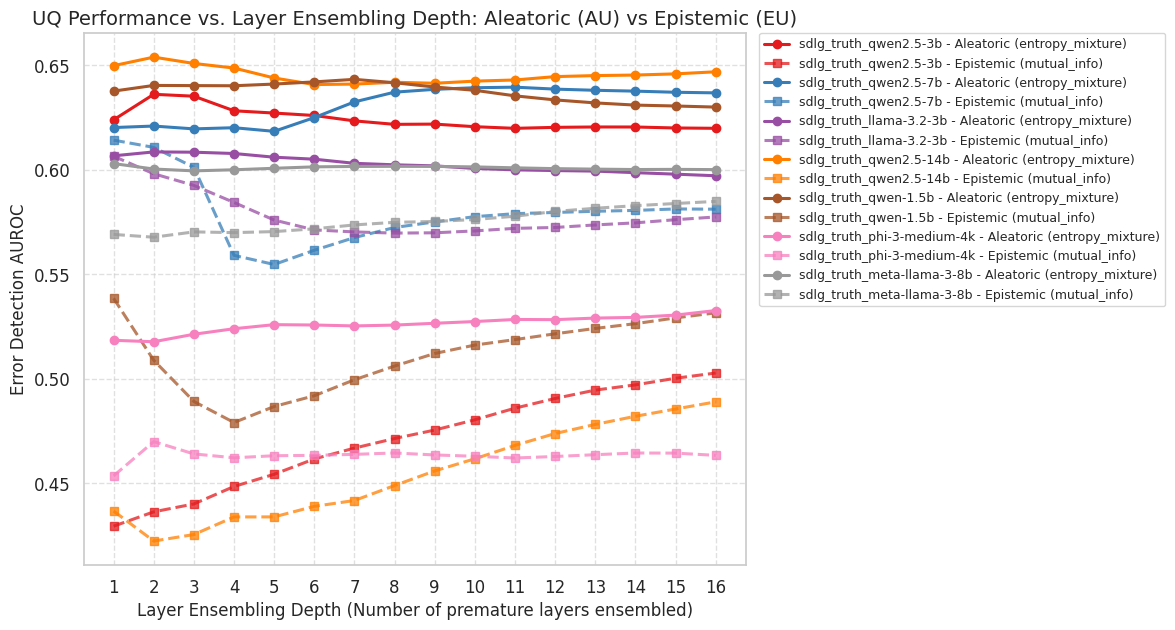

In [20]:
# Layer Ensembling Depth Analysis: Distinct Model Colors & Gated MI Depth Parsing
plt.figure(figsize=(13, 6.2))
has_layer_depth_data = False
all_observed_depths = set()
colors = sns.color_palette('tab10', max(len(runs), 3))

for r_idx, run in enumerate(runs):
    df, _, _ = load_run_data(run)
    if len(df) == 0: continue
    CORR_THRESHOLD = GLOBAL_CORR_THRESHOLD
    df['Is_Correct'] = (df['Correctness'] >= CORR_THRESHOLD).astype(int)
    model_color = colors[r_idx % len(colors)]
    
    # Filter physical layer indices (depth <= 48 to support 14B models)
    em_cols = [c for c in df.columns if c.startswith('entropy_mixture_') and c.replace('entropy_mixture_', '').isdigit() and int(c.replace('entropy_mixture_', '')) < 48]
    
    # Prioritize Gated MI layer keys, fallback to MI layer keys
    gmi_cols = [c for c in df.columns if (c.startswith('gated_mutual_info_') or c.startswith('mutual_info_')) and c.split('_')[-1].isdigit() and int(c.split('_')[-1]) < 48]
    
    if em_cols:
        has_layer_depth_data = True
        em_cols.sort(key=lambda x: int(x.split('_')[-1]))
        
        aurocs_em, depths_em = [], []
        for col in em_cols:
            d_val = int(col.split('_')[-1]) + 1
            if d_val <= 48:
                _, _, auroc, _, _, _, _, _ = get_curves_and_metrics(df, col)
                aurocs_em.append(auroc)
                depths_em.append(d_val)
                all_observed_depths.add(d_val)
            
        if depths_em:
            plt.plot(depths_em, aurocs_em, label=f"{run['name']} - Aleatoric ($H_{{mix}}$)", marker='o', markersize=5, linewidth=2.0, color=model_color)
        
        if gmi_cols:
            gmi_cols.sort(key=lambda x: int(x.split('_')[-1]))
            aurocs_mi, depths_mi = [], []
            seen_depths = set()
            for col in gmi_cols:
                d_val = int(col.split('_')[-1]) + 1
                if d_val <= 48 and d_val not in seen_depths:
                    seen_depths.add(d_val)
                    _, _, auroc, _, _, _, _, _ = get_curves_and_metrics(df, col)
                    aurocs_mi.append(auroc)
                    depths_mi.append(d_val)
                    all_observed_depths.add(d_val)
            if depths_mi:
                plt.plot(depths_mi, aurocs_mi, label=f"{run['name']} - Epistemic (Gated MI)", marker='s', markersize=4.5, linestyle='--', linewidth=1.8, color=model_color, alpha=0.85)

if has_layer_depth_data:
    max_d = max(all_observed_depths) if all_observed_depths else 32
    tick_marks = [1] + [d for d in range(2, max_d + 1, 2)]
    plt.xticks(tick_marks, fontsize=10.5)
    plt.yticks(fontsize=10.5)
    plt.xlim(0.5, max_d + 0.5)
    plt.xlabel("Layer Ensembling Depth (Number of premature layers ensembled)", fontsize=12, fontweight='bold', labelpad=8)
    plt.ylabel("Error Detection AUROC", fontsize=12, fontweight='bold', labelpad=8)
    plt.title("UQ Performance vs. Layer Ensembling Depth: Aleatoric ($H_{mix}$) vs Epistemic (Gated MI)", fontsize=13.5, fontweight='bold', pad=12)
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, fontsize=9.5, frameon=True, framealpha=0.95, edgecolor='#cccccc')
    plt.grid(True, linestyle='--', alpha=0.5, color='#cccccc')
    plt.tight_layout()
    plt.show()
else:
    print("No layer-wise data available.")
